A Simple Guide to Image Classification Using FastAI

This tutorial demonstrates how to train a basic image-classification model using FastAI.

The example dataset contains procedurally generated RGB images of several geometric shapes. The workflow is intentionally simple so that the example data can be replaced with your own images and classification labels.


The first step is to import the Python packages required for the tutorial.

Pandas is used to organise and work with tabular data, while FastAI provides the tools required to construct and train the image-classification model.


In [1]:
import pandas as pd
import os
from fastai.vision.all import *

The following block checks whether the example dataset is already available.

If the required data cannot be found, the notebook runs Generating_basic_data.ipynb to create the example dataset.

If you are using your own dataset, this step can be omitted or modified as required.


In [2]:
Dataframe_path = '../image_data_assorted.csv'

if os.path.exists(Dataframe_path):
    print("The file exists.")
else:
    %run ../Generating_basic_data.ipynb

The file exists.


The next step is to load the dataframe containing the image paths and associated information for each image. For this classification task, the important target variable is the shape column, which contains the class assigned to each image.


In [3]:

df = pd.read_csv(Dataframe_path)

The supplied example dataset contains 1,000 procedurally generated images of geometric shapes.

The two columns required for this tutorial are:

1. image_path: contains the file path used to locate and load each image.

2. shape: contains the ground-truth classification label for each image.


In [4]:
df.head()

,Radius,X_Position,Y_Position,Area,Surface2d,Volume,image_path,mask_path,shape
0,57,82,279,3249,228,185193,../images_assorted/image_1.png,../masks_assorted/mask_1.png,square
1,94,347,290,8836,376,830584,../images_assorted/image_2.png,../masks_assorted/mask_2.png,square
2,42,79,332,1764,168,74088,../images_assorted/image_3.png,../masks_assorted/mask_3.png,square
3,88,248,182,24316,276,2853096,../images_assorted/image_4.png,../masks_assorted/mask_4.png,circle
4,74,430,381,17195,232,1696538,../images_assorted/image_5.png,../masks_assorted/mask_5.png,circle


We next define two functions that specify how FastAI should extract the model inputs and targets from the dataframe. For image classification, the model requires an image as its input and a categorical class label as its target.

During training, each function receives one row of the dataframe as a Pandas Series. The get_inputs function reads the file path stored in the image_path column and loads the corresponding image as a PILImage.

The get_target function extracts the classification label stored in the shape column.


In [5]:
def get_inputs(row):
    # Convert image path to PILImage
    image_path = row['image_path']
    image_data = PILImage.create(image_path)
    return image_data 

def get_target(row):
    # Convert image path to PILImage
    target_data = row['shape']
    return target_data

A FastAI DataBlock defines how the training data are organised and supplied to the model. In this tutorial, only the settings required for a basic image-classification task are used.

The blocks argument specifies the types of input and target data. Because the input is an image and the target is a categorical label, the appropriate configuration is:

blocks=(ImageBlock, CategoryBlock)

ImageBlock specifies that the model input is image data, while CategoryBlock specifies that the target is a categorical classification.

The previously defined getter functions are then assigned using:

get_x=get_inputs
get_y=get_target

Here, get_x specifies how the input data are obtained and get_y specifies how the target data are obtained.

Two additional options are included as commented examples.

RandomSplitter can be used to control how the dataset is divided into training and validation subsets. The role of validation data is discussed in greater detail in the Chapter 2 appendix.

Resize can be used when the input images do not have a consistent resolution. For example, Resize(512) converts the input images to 512 × 512 pixels before they are supplied to the model. Neural-network models require the images within a batch to have consistent dimensions.


In [6]:
dblock = DataBlock(
    blocks=(ImageBlock, CategoryBlock),  # Image input and auxiliary input
    get_x=get_inputs,  # Get both the image path and the auxiliary input
    get_y=get_target  # Get the radius value from the dataframe
    #splitter=RandomSplitter(valid_pct=0.2, seed=42),  # Split into train and validation sets
    #item_tfms=Resize(512)  # Resize images to 512x512

)


The next step is to create the FastAI DataLoaders object from the DataBlock and dataframe.

The bs argument specifies the batch size, which determines how many samples are processed together during each training step.

The appropriate batch size depends primarily on the available GPU memory and the size of the images and model. A larger batch size can improve computational efficiency, but excessively large values can exceed the available memory. A batch size of 64 is used for this example.


In [7]:

dls = dblock.dataloaders(df, bs=64)


Before training, it is useful to inspect several samples produced by the dataloader to confirm that the images and target labels are being loaded correctly.

The following code displays nine randomly selected samples, or fewer if the batch size is smaller, together with their ground-truth classifications.

With the supplied example dataset, the images contain blue geometric shapes on a red background. These colours were selected to provide strong visual contrast while remaining distinguishable for common forms of colour-vision deficiency.


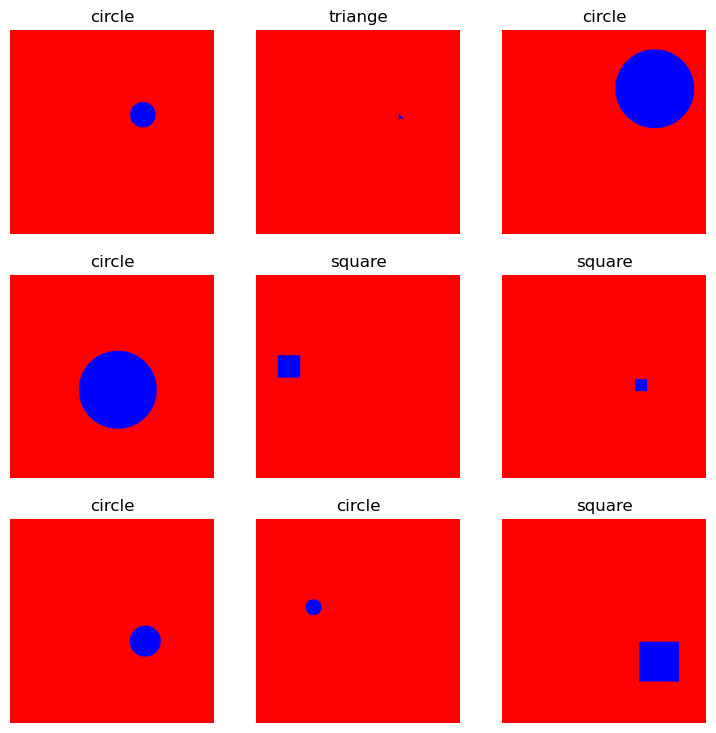

In [8]:
dls.show_batch()

The next step is to create the FastAI Learner, which combines the dataloaders, neural-network architecture, and evaluation metric used during training.

Because the model receives images as input, this tutorial uses FastAI's vision_learner.

Three main inputs are provided: the dataloaders, the model architecture, and the evaluation metric.

This example uses a pretrained ResNet-34 architecture (resnet34). Smaller or larger ResNet architectures can be substituted depending on the complexity of the dataset, available computational resources, and required performance. Common alternatives include resnet18, resnet50, resnet101, and resnet152.

The evaluation metric used here is classification accuracy, which reports the fraction of validation samples assigned to the correct class. Other evaluation approaches are discussed in the Chapter 2 appendix.


In [9]:
# Create and train the learner
learn = vision_learner(dls, resnet34, metrics=accuracy)


Before training, FastAI's learning-rate finder can be used to identify a suitable learning rate. Although default learning rates can often work adequately, the learning-rate finder provides a quick way to select a value appropriate for the current model and dataset.

The resulting plot typically contains a region where the loss begins to decrease rapidly as the learning rate increases. FastAI returns suggested learning rates based on this behaviour.

In this tutorial, both the minimum-loss and steepest-slope suggestions are returned, and the steepest-slope value is subsequently used for training. If the automatically selected value is unsuitable, the plot can also be inspected manually and a learning rate selected from the region where the loss decreases consistently.

Further discussion of learning-rate selection is provided in the Chapter 2 appendix.


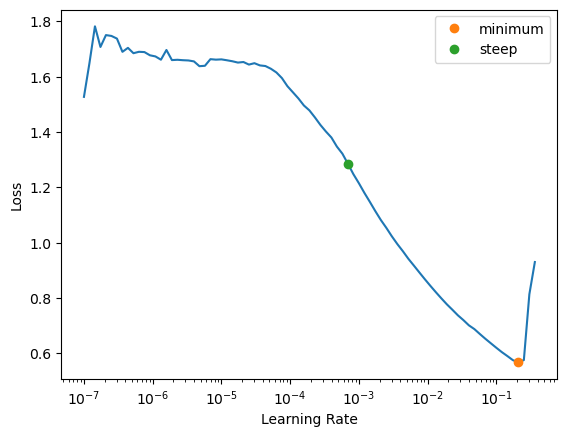

In [10]:
lr_min,lr_steep = learn.lr_find(suggest_funcs=(minimum, steep))

The model can now be trained.

Because resnet34 is loaded with pretrained weights, this tutorial uses FastAI's fine_tune method rather than training the network from randomly initialised weights. Fine-tuning allows the pretrained model to adapt its existing image features to the new classification task.

The first argument specifies the number of training epochs, while base_lr specifies the learning rate identified in the previous step. More detailed discussion of training methods, epochs, and training outputs is provided in the Chapter 2 appendix.


In [11]:
learn.fine_tune(10, base_lr=lr_steep)

epoch,train_loss,valid_loss,accuracy,time
0,1.147953,3.340674,0.375000,00:06


epoch,train_loss,valid_loss,accuracy,time
0,0.189864,1.188888,0.650000,00:08
1,0.112755,0.352848,0.855000,00:07
2,0.069485,0.013747,0.995000,00:07
3,0.046300,0.011393,0.995000,00:07
4,0.033425,0.020177,0.995000,00:08
5,0.024796,0.007028,0.995000,00:09
6,0.018442,0.000093,1.000000,00:07
7,0.013998,0.000074,1.000000,00:07
8,0.010938,0.000080,1.000000,00:07
9,0.008474,0.000062,1.000000,00:07


After training, the model should be evaluated to determine whether training behaved appropriately and whether its predictions are sufficiently accurate for the intended application.

There are many approaches to model evaluation. This tutorial demonstrates two useful introductory methods: examining the training and validation losses and inspecting a confusion matrix.


The first evaluation step is to plot the training and validation loss values across the training epochs.

These curves provide information about how the model learned during training and can help identify problems such as overfitting, underfitting, or training that stopped before convergence. Loss curves do not directly establish whether the model is sufficiently accurate for its intended use, but they are useful for diagnosing the training process. Further discussion is provided in the Chapter 2 appendix.


<bound method Recorder.plot_loss of Recorder>


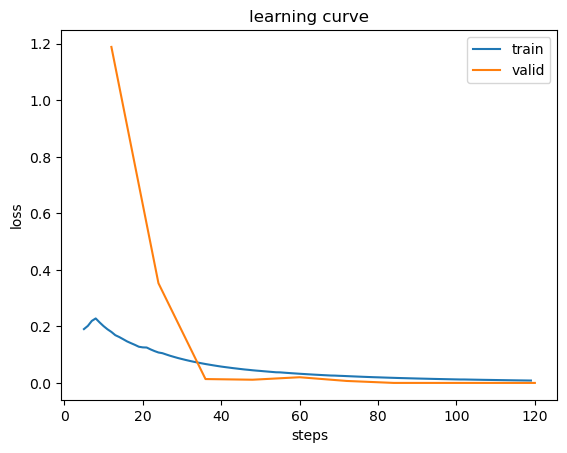

In [12]:
# Plot the losses
learn.recorder.plot_loss()
print(learn.recorder.plot_loss)

# Set the y-axis limits (replace with your desired limits)
#plt.ylim(0, 5)  # sets y-axis limits 

# Show the plot with updated y-limits
plt.show()

In a successful training run, the training and validation losses should generally decrease and then stabilise. A sustained increase in validation loss while training loss continues to decrease can indicate overfitting, while both losses continuing to decrease at the end of training can indicate that additional training may still improve the model. These patterns should be interpreted alongside task-specific performance metrics rather than using a fixed numerical difference between the two losses.


Evaluating classification performance

For classification models, a confusion matrix provides a useful summary of prediction performance across the different classes.

The following code calculates a confusion matrix using the validation dataset. Each row and column represents a class, allowing correct classifications and common misclassifications to be identified directly.


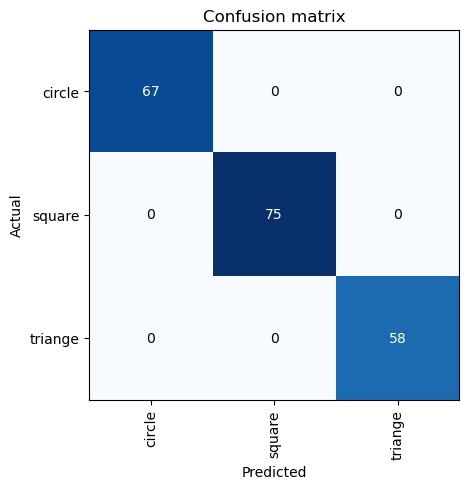

In [13]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

Exporting and using the trained model


Saving the trained model

The trained learner can be exported to a .pkl file using learn.export(). This file can subsequently be loaded without retraining the model.


In [14]:
learn.export('exported_classification_model.pkl')

Loading an exported model

An exported FastAI learner can be loaded using load_learner() by providing the path to the exported .pkl file.

For simple image inputs, an image or image path can then be supplied directly to the loaded learner. More complex models may also require any custom functions or classes used when the learner was originally created to be available when the model is loaded.

The loaded object provides the same FastAI Learner interface used during training and can therefore be used directly for inference.


In [15]:
# import

learn2 = load_learner('exported_classification_model.pkl')   # using learner2 to show its loading

C:\Users\bowan\anaconda3\Lib\site-packages\fastai\learner.py:455: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


The following example loads an image from the dataframe and passes it to the exported model for classification.

The predict method performs inference on the supplied image and returns three outputs describing the predicted class and associated probabilities.


In [16]:
# just getting a random image from df
image_paths = df['image_path']
i = 1 # row/sample number from the dataframe
image_data = PILImage.create(image_paths[i]) # just gets a generic image
Prediction, ClassID, Confidence =learn2.predict(image_data)

The model returns three values for each prediction:

Prediction: the predicted class label.

ClassID: the numerical index corresponding to the predicted class.

Confidence: the predicted probability for each available class.


In [17]:
print(Prediction)
print(ClassID)
print(Confidence)

square
tensor(1)
tensor([5.7708e-07, 1.0000e+00, 1.1212e-06])


Displaying the image and predicted classification

The following code displays the input image together with the predicted class, allowing the prediction to be inspected visually.


square


<Axes: >

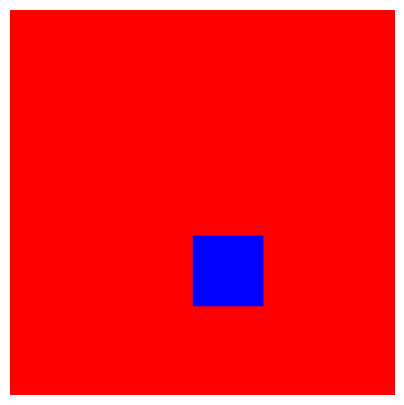

In [18]:
print(Prediction)
image_data.show()

This completes the basic image-classification workflow. The tutorial has demonstrated how to organise labelled image data, construct a FastAI DataBlock, create and train a pretrained image-classification model, evaluate its performance, export the trained model, and use it to classify new images. The same general workflow can be adapted to more complex image-classification problems by replacing the example dataset and adjusting the model and training settings as required.
